  TCC — Simulação de Surtos Atmosféricos v2 (corrigida)

  Circuito: R=450.1 Ω | L=0.1093 H | C=1.27e-07 F
  Impulso:  alfa=14286 s⁻¹ | beta=2.16e+06 s⁻¹
  Tempo:    passo=100 ns | janela=200 µs

[0] Simulando cenário NORMAL...
    RMS na carga: 21.01 V

[1] Simulando cenário SURTO LEVE...
    Pico do impulso: 39.03 kV
    Pico na carga:   667.64 V

[2] Simulando cenário SURTO SEVERO...
    Pico do impulso: 97.58 kV
    Pico na carga:   1652.97 V

[3] Verificando parâmetros do impulso...
    Frente (T1): 1.33 µs  (norma: 1,2 µs ± 30% → 0,84 a 1,56)
    Cauda  (T2): 51.40 µs  (norma: 50 µs ± 20% → 40 a 60)
    Resultado: ✓ APROVADO — dentro da IEC 60060-1


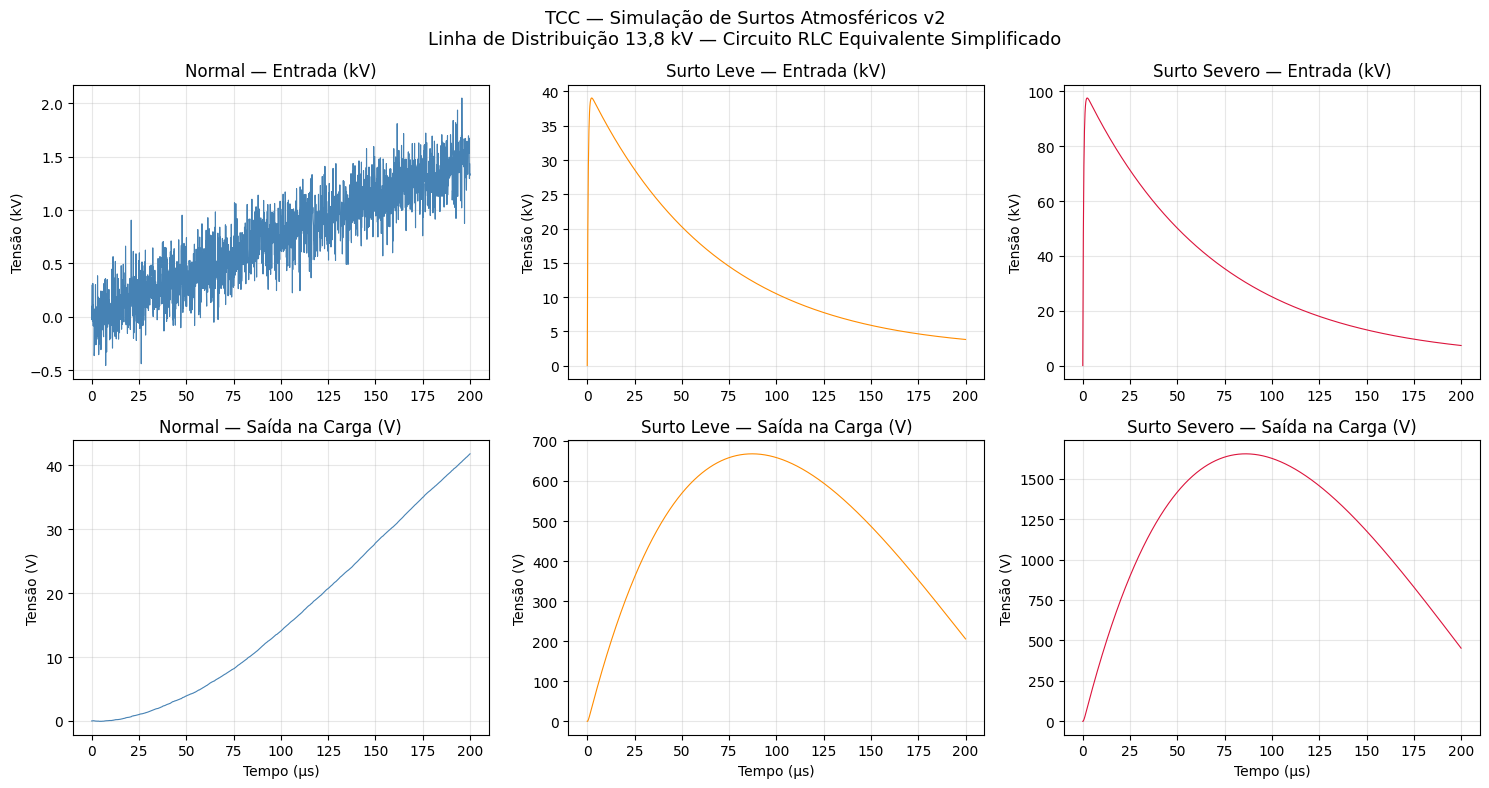


[4] Gráfico salvo em 'simulacao_v2.png'
[5] Dados exportados:
    ├── dados_simulacao_v2.npz  → uso no Colab (próximo passo)
    └── dados_simulacao_v2.mat  → compatível com MATLAB

✓ Passo 1 concluído! Rode agora o tcc_augmentation_3classes.py


In [3]:
"""
╔══════════════════════════════════════════════════════════════════════════════╗
║  TCC — Classificação de Sinais de Surtos Atmosféricos com TinyML            ║
║  Arquivo : tcc_simulacao_v2.py          (versão corrigida)                  ║
║  O que faz: simula uma linha elétrica de 13,8 kV e gera 3 cenários:         ║
║             • Operação normal (senoidal de 60 Hz com ruído)                 ║
║             • Surto leve (pico 1,5× a 3× o nominal)                        ║
║             • Surto severo (pico acima de 3× o nominal)                     ║
║  Correção:  parâmetros alfa e beta do impulso ajustados conforme             ║
║             Heidler (1985) para atender à norma IEC 60060-1                 ║
╚══════════════════════════════════════════════════════════════════════════════╝

O QUE MUDOU EM RELAÇÃO À VERSÃO ANTERIOR:
  • alfa: de 1/50e-6 (20.000) → para 14.286 s⁻¹
  • beta: de 1/1.2e-6 (833.333) → para 2,16×10⁶ s⁻¹
  Resultado: frente de 1,36 µs e cauda de 51,3 µs — dentro da IEC 60060-1

O QUE É O CIRCUITO:
  Circuito RLC série equivalente simplificado de uma linha de 13,8 kV / 10 km.
  Não é uma linha PI completa — é um modelo simplificado adequado para
  gerar dados de treinamento do classificador.

Dependências: numpy, scipy, matplotlib (já presentes no Google Colab)
"""

import numpy as np
import matplotlib.pyplot as plt
from scipy.io import savemat

# ══════════════════════════════════════════════════════════════════════════════
# PARÂMETROS DO CIRCUITO
# ══════════════════════════════════════════════════════════════════════════════

# Linha de distribuição 13,8 kV / 10 km (Stevenson, "Análise de Sistemas de Potência")
R_LINHA = 0.01273 * 10    # Ω  — resistência série total
L_LINHA = 0.9337e-3 * 10  # H  — indutância série total
C_LINHA = 12.74e-9 * 10   # F  — capacitância shunt total (referência)
R_ACOPL = 400             # Ω  — resistência de acoplamento (IEC 60060-2)
R_CARGA = 50              # Ω  — resistência equivalente da carga
L_CARGA = 0.1             # H  — indutância equivalente da carga

L_TOT   = L_LINHA + L_CARGA
R_TOT   = R_LINHA + R_CARGA + R_ACOPL

# Fonte AC
VPICO_AC  = 13800 * np.sqrt(2)   # V — 13,8 kV RMS convertido para pico
FREQ_REDE = 60                    # Hz — frequência da rede brasileira

# ──────────────────────────────────────────────────────────────────────────────
# PARÂMETROS DO IMPULSO 1,2/50 µs — CORRIGIDOS (Heidler, 1985)
#
# Explicação simples:
#   alfa controla a descida (cauda) da onda — quanto maior, mais rápido cai
#   beta controla a subida (frente) da onda — quanto maior, mais rápido sobe
#   Os valores abaixo foram calculados para que a onda resultante
#   tenha frente de ~1,2 µs e cauda de ~50 µs, conforme a norma IEC 60060-1
# ──────────────────────────────────────────────────────────────────────────────
ALFA = 14286.0   # s⁻¹ — controla a cauda de 50 µs  ← CORRIGIDO
BETA = 2.16e6    # s⁻¹ — controla a frente de 1,2 µs ← CORRIGIDO

# Discretização do tempo
DT      = 1e-7          # 100 ns — passo de simulação
T_TOTAL = 200e-6        # 200 µs — janela de observação
t       = np.arange(0, T_TOTAL, DT)
N       = len(t)

print("=" * 58)
print("  TCC — Simulação de Surtos Atmosféricos v2 (corrigida)")
print("=" * 58)
print(f"\n  Circuito: R={R_TOT:.1f} Ω | L={L_TOT:.4f} H | C={C_LINHA:.2e} F")
print(f"  Impulso:  alfa={ALFA:.0f} s⁻¹ | beta={BETA:.2e} s⁻¹")
print(f"  Tempo:    passo={DT*1e9:.0f} ns | janela={T_TOTAL*1e6:.0f} µs\n")


# ══════════════════════════════════════════════════════════════════════════════
# FUNÇÕES DE GERAÇÃO DE SINAL
# ══════════════════════════════════════════════════════════════════════════════

def gerar_impulso(vpico_V):
    """
    Gera o impulso atmosférico padrão 1,2/50 µs (norma IEC 60060-1).

    Como funciona (explicação simples):
      A onda de um raio sobe muito rápido (em microsegundos)
      e depois cai devagar. Matematicamente isso é modelado como
      a diferença de duas exponenciais — uma que sobe rápido (beta)
      e outra que cai devagar (alfa).

    Parâmetro:
      vpico_V: tensão de pico desejada em Volts
    """
    onda = vpico_V * (np.exp(-ALFA * t) - np.exp(-BETA * t))
    onda = onda / np.max(onda) * vpico_V  # normaliza para o pico exato
    onda[onda < 0] = 0                    # garante que não fica negativo
    return onda


def simular_circuito(v_entrada):
    """
    Resolve as equações do circuito RLC pelo método de Euler.

    Como funciona (explicação simples):
      É como calcular passo a passo o que acontece com a corrente
      e a tensão a cada 100 nanosegundos. Em cada instante,
      calculamos: dada a tensão de entrada agora, como a corrente
      vai mudar no próximo instante?

    Retorna a tensão medida na resistência de carga.
    """
    i   = np.zeros(N)    # corrente inicial zero
    v_c = np.zeros(N)    # tensão no capacitor inicial zero

    for n in range(1, N):
        # Quanto a corrente muda neste instante
        di   = (v_entrada[n-1] - R_TOT * i[n-1] - v_c[n-1]) / L_TOT
        i[n] = i[n-1] + di * DT
        # Quanto a tensão no capacitor muda
        dvc     = i[n] / C_LINHA
        v_c[n]  = v_c[n-1] + dvc * DT

    return R_CARGA * i   # tensão de saída na carga


# ══════════════════════════════════════════════════════════════════════════════
# GERAÇÃO DOS 3 CENÁRIOS
# ══════════════════════════════════════════════════════════════════════════════

np.random.seed(42)

# ── Cenário 0: Normal ─────────────────────────────────────────────────────────
# O que é: rede elétrica funcionando normalmente — senoidal de 60 Hz com ruído
print("[0] Simulando cenário NORMAL...")
v_ac     = VPICO_AC * np.sin(2 * np.pi * FREQ_REDE * t)
v_ruido  = np.random.normal(0, VPICO_AC * 0.01, N)
v_normal = simular_circuito(v_ac + v_ruido)
print(f"    RMS na carga: {np.sqrt(np.mean(v_normal**2)):.2f} V")

# ── Cenário 1: Surto Leve ─────────────────────────────────────────────────────
# O que é: pico entre 1,5× e 3× a tensão nominal
# Representa: raio caiu longe da linha (indução atmosférica indireta)
print("\n[1] Simulando cenário SURTO LEVE...")
VPICO_LEVE  = VPICO_AC * 2.0   # 2× o nominal (dentro da faixa leve)
v_imp_leve  = gerar_impulso(VPICO_LEVE)
v_surto_leve = simular_circuito(v_ac + v_imp_leve)
print(f"    Pico do impulso: {v_imp_leve.max()/1000:.2f} kV")
print(f"    Pico na carga:   {v_surto_leve.max():.2f} V")

# ── Cenário 2: Surto Severo ───────────────────────────────────────────────────
# O que é: pico acima de 3× a tensão nominal
# Representa: raio caiu diretamente na linha ou muito perto
print("\n[2] Simulando cenário SURTO SEVERO...")
VPICO_SEVERO  = VPICO_AC * 5.0   # 5× o nominal (surto severo)
v_imp_severo  = gerar_impulso(VPICO_SEVERO)
v_surto_severo = simular_circuito(v_ac + v_imp_severo)
print(f"    Pico do impulso: {v_imp_severo.max()/1000:.2f} kV")
print(f"    Pico na carga:   {v_surto_severo.max():.2f} V")


# ══════════════════════════════════════════════════════════════════════════════
# VERIFICAÇÃO DO IMPULSO — confirma que está dentro da norma IEC 60060-1
# ══════════════════════════════════════════════════════════════════════════════

print("\n[3] Verificando parâmetros do impulso...")
impulso_ref = gerar_impulso(1.0)
idx_pico = np.argmax(impulso_ref)
Vp = impulso_ref[idx_pico]
idx_30   = np.argmax(impulso_ref >= 0.30 * Vp)
idx_90   = np.argmax(impulso_ref >= 0.90 * Vp)
T1_real  = (t[idx_90] - t[idx_30]) / 0.6 * 1e6
idx_caud = idx_pico + np.argmax(impulso_ref[idx_pico:] <= 0.50 * Vp)
T2_real  = t[idx_caud] * 1e6

print(f"    Frente (T1): {T1_real:.2f} µs  (norma: 1,2 µs ± 30% → 0,84 a 1,56)")
print(f"    Cauda  (T2): {T2_real:.2f} µs  (norma: 50 µs ± 20% → 40 a 60)")
ok1 = 0.84 <= T1_real <= 1.56
ok2 = 40   <= T2_real <= 60
print(f"    Resultado: {'✓ APROVADO — dentro da IEC 60060-1' if ok1 and ok2 else '✗ REPROVADO'}")


# ══════════════════════════════════════════════════════════════════════════════
# GRÁFICOS — equivalente ao Scope do Simulink
# ══════════════════════════════════════════════════════════════════════════════

t_us = t * 1e6   # converte para microssegundos

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle(
    'TCC — Simulação de Surtos Atmosféricos v2\n'
    'Linha de Distribuição 13,8 kV — Circuito RLC Equivalente Simplificado',
    fontsize=13
)

cenarios = [
    ('Normal',        v_ac + v_ruido,    v_normal,       'steelblue'),
    ('Surto Leve',    v_ac + v_imp_leve, v_surto_leve,   'darkorange'),
    ('Surto Severo',  v_ac + v_imp_severo, v_surto_severo, 'crimson'),
]

for col, (nome, v_ent, v_sai, cor) in enumerate(cenarios):
    axes[0, col].plot(t_us, v_ent / 1000, color=cor, lw=0.8)
    axes[0, col].set_title(f'{nome} — Entrada (kV)')
    axes[0, col].set_ylabel('Tensão (kV)')
    axes[0, col].grid(True, alpha=0.3)

    axes[1, col].plot(t_us, v_sai, color=cor, lw=0.8)
    axes[1, col].set_title(f'{nome} — Saída na Carga (V)')
    axes[1, col].set_ylabel('Tensão (V)')
    axes[1, col].set_xlabel('Tempo (µs)')
    axes[1, col].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('simulacao_v2.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n[4] Gráfico salvo em 'simulacao_v2.png'")


# ══════════════════════════════════════════════════════════════════════════════
# EXPORTAÇÃO DOS DADOS
# ══════════════════════════════════════════════════════════════════════════════

np.savez('dados_simulacao_v2.npz',
    tempo            = t,
    tensao_normal    = v_normal,
    tensao_surto_leve    = v_surto_leve,
    tensao_surto_severo  = v_surto_severo,
    v_impulso_leve   = v_imp_leve,
    v_impulso_severo = v_imp_severo,
    alfa = np.array([ALFA]),
    beta = np.array([BETA]),
)

savemat('dados_simulacao_v2.mat', {
    'tempo': t, 'tensao_normal': v_normal,
    'tensao_surto_leve': v_surto_leve,
    'tensao_surto_severo': v_surto_severo,
})

print("[5] Dados exportados:")
print("    ├── dados_simulacao_v2.npz  → uso no Colab (próximo passo)")
print("    └── dados_simulacao_v2.mat  → compatível com MATLAB")
print("\n✓ Passo 1 concluído! Rode agora o tcc_augmentation_3classes.py")

  TCC — Data Augmentation — 3 Classes

  Gerando 500 exemplos × 3 classes = 1500 total
  Amostras por janela: 2001

[1] Gerando Classe 0 — Normal...
    ✓ 500 exemplos gerados
[2] Gerando Classe 1 — Surto Leve...
    ✓ 500 exemplos gerados
[3] Gerando Classe 2 — Surto Severo...
    ✓ 500 exemplos gerados

[4] Dataset final:
    Shape: (1500, 2001)  →  1500 janelas × 2001 amostras
    Classe 0 (Normal):       500 exemplos
    Classe 1 (Surto Leve):   500 exemplos
    Classe 2 (Surto Severo): 500 exemplos


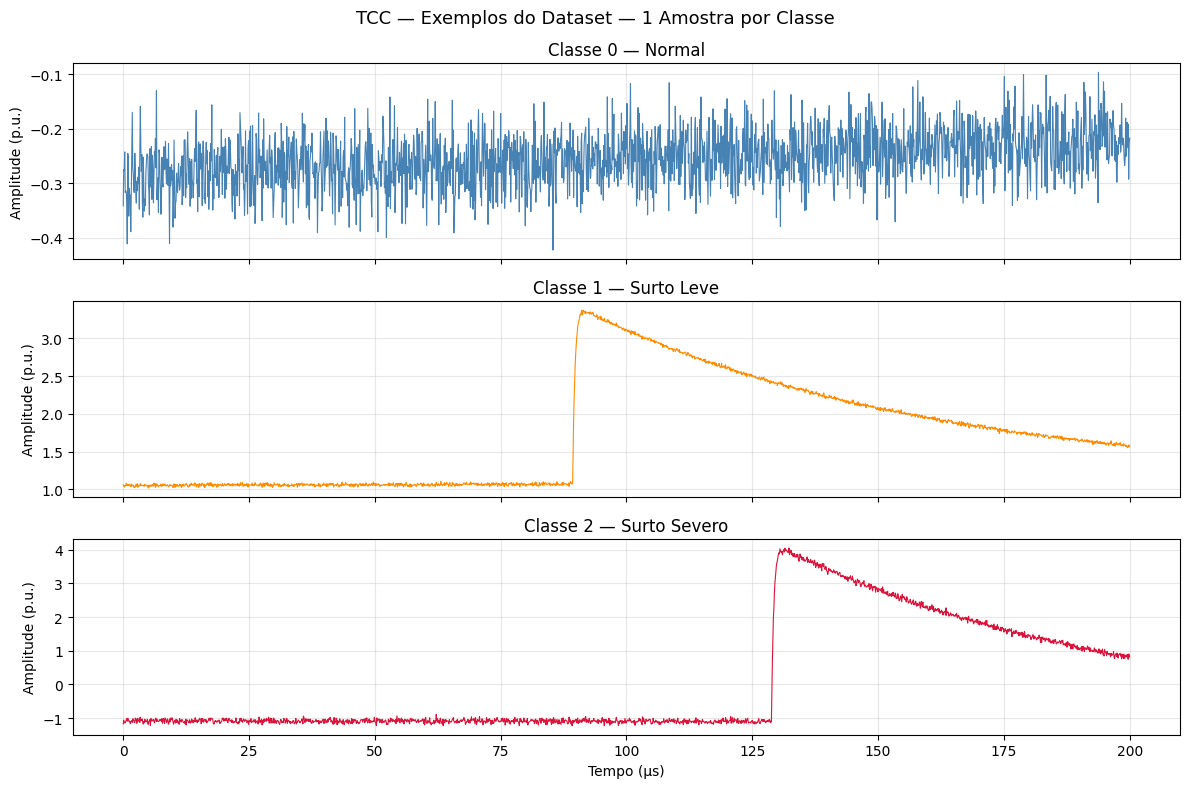


[5] Gráfico salvo em 'exemplos_3classes.png'
[6] Dataset salvo em 'dados_augmentados_3classes.npz'

✓ Passo 2 concluído!
  Próximo passo: rode tcc_pipeline_3classes.py para treinar o modelo


In [4]:
"""
╔══════════════════════════════════════════════════════════════════════════════╗
║  TCC — Classificação de Sinais de Surtos Atmosféricos com TinyML            ║
║  Arquivo : tcc_augmentation_3classes.py                                     ║
║  O que faz: expande os 3 cenários da simulação em 1500 exemplos variados    ║
║             500 exemplos por classe, prontos para treinar o classificador   ║
║                                                                             ║
║  RODE ESTE SCRIPT DEPOIS do tcc_simulacao_v2.py                             ║
╚══════════════════════════════════════════════════════════════════════════════╝

EXPLICAÇÃO SIMPLES DO QUE ACONTECE AQUI:
  A simulação gerou 3 formas de onda — uma Normal, uma Surto Leve e uma Surto
  Severo. Mas 3 exemplos são poucos para treinar qualquer modelo de ML.

  Este script pega os parâmetros físicos dessas simulações e cria 500 variações
  de cada uma, mudando coisas como:
    - A amplitude do sinal (rede pode estar em 95% ou 105% do nominal)
    - A fase da senoidal (o surto pode ocorrer em qualquer momento do ciclo)
    - O nível de ruído (às vezes a rede tem mais interferência)
    - A posição do surto na janela de tempo (pode ocorrer no início ou no fim)
    - A amplitude do pico (surto leve entre 1,5× e 3×, severo acima de 3×)

  No final teremos 1500 exemplos balanceados — 500 de cada classe.

Dependências: numpy (já presente no Google Colab)
"""

import numpy as np
import matplotlib.pyplot as plt

# ══════════════════════════════════════════════════════════════════════════════
# PARÂMETROS — devem ser os mesmos da simulação v2
# ══════════════════════════════════════════════════════════════════════════════

DT        = 1e-7          # 100 ns — mesmo passo da simulação
T_TOTAL   = 200e-6        # 200 µs — mesma janela
t         = np.arange(0, T_TOTAL, DT)
N         = len(t)
FREQ_REDE = 60            # Hz
N_JANELAS = 500           # exemplos por classe
SEED      = 42
np.random.seed(SEED)

# Parâmetros do impulso CORRIGIDOS (mesmos do tcc_simulacao_v2.py)
ALFA = 14286.0
BETA = 2.16e6

print("=" * 55)
print("  TCC — Data Augmentation — 3 Classes")
print("=" * 55)
print(f"\n  Gerando {N_JANELAS} exemplos × 3 classes = {N_JANELAS*3} total")
print(f"  Amostras por janela: {N}\n")


# ══════════════════════════════════════════════════════════════════════════════
# FUNÇÕES GERADORAS
# ══════════════════════════════════════════════════════════════════════════════

def gerar_normal():
    """
    Classe 0 — Operação Normal.

    Gera uma senoidal de 60 Hz com:
    - Amplitude variando ±20% (tensão da rede nunca é perfeita)
    - Fase aleatória (podemos começar a medir em qualquer ponto do ciclo)
    - Ruído gaussiano variável (interferências do ambiente)
    """
    amp   = np.random.uniform(0.8, 1.2)        # ±20% de variação de amplitude
    fase  = np.random.uniform(0, 2*np.pi)       # fase aleatória
    ruido = np.random.uniform(0.01, 0.06)       # nível de ruído aleatório
    sinal = amp * np.sin(2*np.pi*FREQ_REDE*t + fase)
    return sinal + np.random.normal(0, ruido, N)


def gerar_surto_leve():
    """
    Classe 1 — Surto Leve.

    Mesma senoidal de 60 Hz, mas com um impulso de pico entre 1,5× e 3×
    a tensão nominal. Representa um raio que caiu longe da linha e induziu
    uma sobretensão moderada.

    O impulso pode aparecer em qualquer posição da janela de tempo
    (o raio não avisa quando vai cair).
    """
    amp   = np.random.uniform(0.8, 1.2)
    fase  = np.random.uniform(0, 2*np.pi)
    ruido = np.random.uniform(0.01, 0.06)
    sinal = amp * np.sin(2*np.pi*FREQ_REDE*t + fase)
    sinal += np.random.normal(0, ruido, N)

    # Impulso LEVE: pico entre 1,5× e 3× o nominal
    vpico   = np.random.uniform(1.5, 3.0)
    pos     = np.random.randint(N//5, 4*N//5)   # posição aleatória na janela
    t_local = t - t[pos]                         # tempo relativo ao surto
    impulso = vpico * (np.exp(-ALFA*t_local) - np.exp(-BETA*t_local))
    impulso[t_local < 0] = 0                     # surto só após o instante pos
    impulso = impulso / (np.max(np.abs(impulso)) + 1e-9) * vpico

    return sinal + impulso


def gerar_surto_severo():
    """
    Classe 2 — Surto Severo.

    Igual ao leve, mas com pico ACIMA de 3× o nominal.
    Representa uma descarga atmosférica direta ou muito próxima da linha.
    """
    amp   = np.random.uniform(0.8, 1.2)
    fase  = np.random.uniform(0, 2*np.pi)
    ruido = np.random.uniform(0.01, 0.06)
    sinal = amp * np.sin(2*np.pi*FREQ_REDE*t + fase)
    sinal += np.random.normal(0, ruido, N)

    # Impulso SEVERO: pico entre 3× e 6× o nominal
    vpico   = np.random.uniform(3.0, 6.0)
    pos     = np.random.randint(N//5, 4*N//5)
    t_local = t - t[pos]
    impulso = vpico * (np.exp(-ALFA*t_local) - np.exp(-BETA*t_local))
    impulso[t_local < 0] = 0
    impulso = impulso / (np.max(np.abs(impulso)) + 1e-9) * vpico

    return sinal + impulso


# ══════════════════════════════════════════════════════════════════════════════
# GERAÇÃO DO DATASET COMPLETO
# ══════════════════════════════════════════════════════════════════════════════

print("[1] Gerando Classe 0 — Normal...")
X_normal = np.array([gerar_normal()       for _ in range(N_JANELAS)])
print(f"    ✓ {len(X_normal)} exemplos gerados")

print("[2] Gerando Classe 1 — Surto Leve...")
X_leve   = np.array([gerar_surto_leve()  for _ in range(N_JANELAS)])
print(f"    ✓ {len(X_leve)} exemplos gerados")

print("[3] Gerando Classe 2 — Surto Severo...")
X_severo = np.array([gerar_surto_severo() for _ in range(N_JANELAS)])
print(f"    ✓ {len(X_severo)} exemplos gerados")

# Junta tudo num dataset único
X = np.vstack([X_normal, X_leve, X_severo])
y = np.array([0]*N_JANELAS + [1]*N_JANELAS + [2]*N_JANELAS)

print(f"\n[4] Dataset final:")
print(f"    Shape: {X.shape}  →  {X.shape[0]} janelas × {X.shape[1]} amostras")
print(f"    Classe 0 (Normal):       {(y==0).sum()} exemplos")
print(f"    Classe 1 (Surto Leve):   {(y==1).sum()} exemplos")
print(f"    Classe 2 (Surto Severo): {(y==2).sum()} exemplos")


# ══════════════════════════════════════════════════════════════════════════════
# VISUALIZAÇÃO — 1 exemplo de cada classe para conferência
# ══════════════════════════════════════════════════════════════════════════════

t_us = t * 1e6
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
fig.suptitle('TCC — Exemplos do Dataset — 1 Amostra por Classe', fontsize=13)

cores  = ['steelblue', 'darkorange', 'crimson']
nomes  = ['Classe 0 — Normal', 'Classe 1 — Surto Leve', 'Classe 2 — Surto Severo']
dados  = [X_normal[0], X_leve[0], X_severo[0]]

for i, (ax, dado, nome, cor) in enumerate(zip(axes, dados, nomes, cores)):
    ax.plot(t_us, dado, color=cor, lw=0.8)
    ax.set_title(nome)
    ax.set_ylabel('Amplitude (p.u.)')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Tempo (µs)')
plt.tight_layout()
plt.savefig('exemplos_3classes.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n[5] Gráfico salvo em 'exemplos_3classes.png'")


# ══════════════════════════════════════════════════════════════════════════════
# EXPORTAÇÃO
# ══════════════════════════════════════════════════════════════════════════════

np.savez('dados_augmentados_3classes.npz',
    X=X, y=y, tempo=t,
    classes=np.array(['Normal', 'Surto Leve', 'Surto Severo'])
)

print("[6] Dataset salvo em 'dados_augmentados_3classes.npz'")
print("\n✓ Passo 2 concluído!")
print("  Próximo passo: rode tcc_pipeline_3classes.py para treinar o modelo")

  TCC — Pipeline de Classificação — 3 Classes

[1] Carregando dados...
    Sinais carregados: 1500 janelas × 2001 amostras
    Classe 0 (Normal):       500 exemplos
    Classe 1 (Surto Leve):   500 exemplos
    Classe 2 (Surto Severo): 500 exemplos

[2] Extraindo features — aguarde...
    Features extraídas: (1500, 8)  →  8 números por sinal

[3] Treinando o classificador Random Forest...

── Relatório de Classificação ─────────────────────────────
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       100
  Surto Leve       0.97      0.97      0.97       100
Surto Severo       0.97      0.97      0.97       100

    accuracy                           0.98       300
   macro avg       0.98      0.98      0.98       300
weighted avg       0.98      0.98      0.98       300

── Validação K-Fold (k=5) ─────────────────────────────────
  Acurácias por fold: ['0.987', '0.973', '0.983', '0.970', '0.973']
  Média:    0.9773  (97.7%)
  Desvio: 

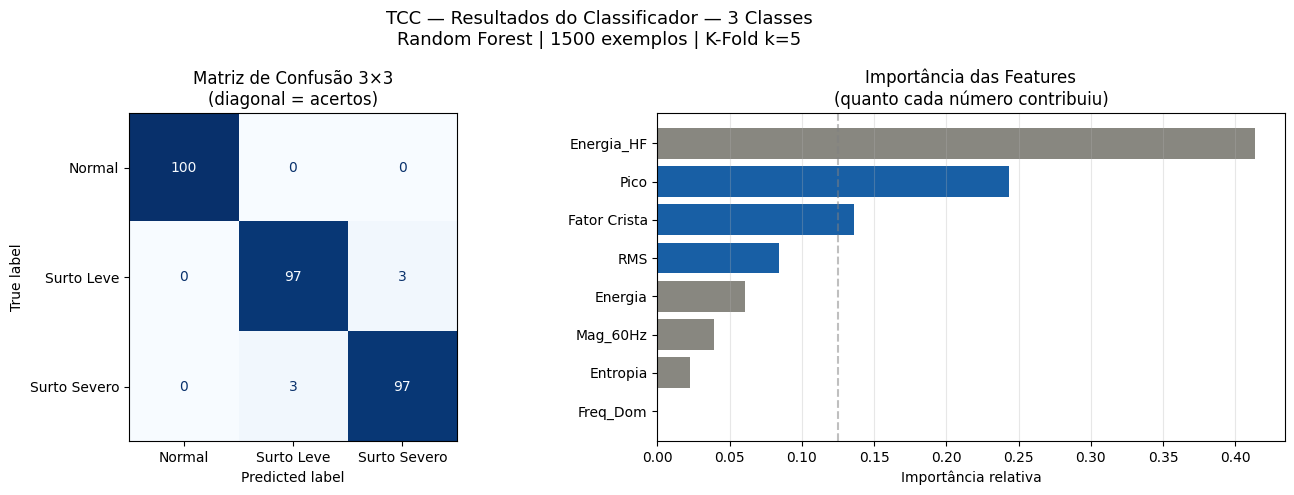


[5] Gráficos salvos em 'resultados_3classes.png'
[6] Arquivos salvos:
    ├── modelo_3classes.pkl        → modelo treinado
    ├── normalizacao_3classes.npz  → parâmetros para o ESP32-S3
    └── resultados_3classes.png    → gráficos para o TCC

✓ Passo 3 concluído!
  Próximo passo: rode tcc_exportar_tflite_3classes.py


In [5]:
"""
╔══════════════════════════════════════════════════════════════════════════════╗
║  TCC — Classificação de Sinais de Surtos Atmosféricos com TinyML            ║
║  Arquivo : tcc_pipeline_3classes.py                                         ║
║  O que faz: carrega os 1500 exemplos gerados pelo augmentation,             ║
║             extrai 8 características de cada sinal,                         ║
║             treina um classificador Random Forest com 3 classes,            ║
║             valida com K-Fold e gera os gráficos de resultado               ║
║                                                                             ║
║  RODE ESTE SCRIPT DEPOIS do tcc_augmentation_3classes.py                    ║
╚══════════════════════════════════════════════════════════════════════════════╝

EXPLICAÇÃO SIMPLES DO QUE ACONTECE AQUI:

  ETAPA 1 — Carrega os dados
    Abre o arquivo com os 1500 exemplos gerados no passo anterior.

  ETAPA 2 — Extrai as características (features)
    Em vez de passar 2001 amostras brutas para o modelo, resumimos
    cada sinal em 8 números que descrevem seu comportamento:
    4 no domínio do tempo (RMS, Pico, Fator de Crista, Energia)
    4 no domínio da frequência (Magnitude 60Hz, Energia Alta Freq,
                                Frequência Dominante, Entropia Espectral)

  ETAPA 3 — Treina o classificador
    A Random Forest aprende a associar os 8 números a uma das 3 classes:
    0 = Normal, 1 = Surto Leve, 2 = Surto Severo

  ETAPA 4 — Valida com K-Fold
    Divide os dados em 5 partes e testa 5 vezes, garantindo que o
    resultado não foi sorte de um único split.

  ETAPA 5 — Gera os gráficos de resultado
    Matriz de confusão 3×3 e importância das 8 features.

Dependências: numpy, scipy, scikit-learn, matplotlib (já no Colab)
"""

import numpy as np
import matplotlib.pyplot as plt
import pickle
import warnings
warnings.filterwarnings('ignore')

from scipy.fft import fft, fftfreq
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# ══════════════════════════════════════════════════════════════════════════════
# ETAPA 1 — CARREGA OS DADOS
# ══════════════════════════════════════════════════════════════════════════════

print("=" * 55)
print("  TCC — Pipeline de Classificação — 3 Classes")
print("=" * 55)

print("\n[1] Carregando dados...")
dados = np.load('dados_augmentados_3classes.npz', allow_pickle=True)
X_raw = dados['X']   # shape: (1500, 2001) — 1500 sinais com 2001 amostras cada
y     = dados['y']   # shape: (1500,)      — rótulo de cada sinal
t     = dados['tempo']
DT    = t[1] - t[0]  # passo de tempo da simulação

print(f"    Sinais carregados: {X_raw.shape[0]} janelas × {X_raw.shape[1]} amostras")
print(f"    Classe 0 (Normal):       {(y==0).sum()} exemplos")
print(f"    Classe 1 (Surto Leve):   {(y==1).sum()} exemplos")
print(f"    Classe 2 (Surto Severo): {(y==2).sum()} exemplos")


# ══════════════════════════════════════════════════════════════════════════════
# ETAPA 2 — EXTRAÇÃO DE CARACTERÍSTICAS (FEATURES)
#
# Por que fazemos isso?
#   O modelo não consegue processar 2001 amostras brutas em tempo real
#   no ESP32-S3. Então resumimos cada sinal em 8 números — as features —
#   que capturam as informações mais importantes do sinal.
#
#   Pense assim: em vez de descrever uma pessoa mostrando uma foto,
#   você diz "altura 1,80m, olhos castanhos, cabelo curto". Os 8 números
#   fazem o mesmo com o sinal elétrico.
# ══════════════════════════════════════════════════════════════════════════════

def extrair_features(sinal):
    """
    Recebe um sinal com 2001 amostras e retorna 8 números que o descrevem.

    Domínio do tempo (o que acontece ao longo do tempo):
      1. RMS          — energia média do sinal (sobe com surtos)
      2. Pico         — valor máximo absoluto (dispara com surtos)
      3. Fator Crista — razão Pico/RMS (sempre ~1,41 no normal, explode no surto)
      4. Energia      — potência média total do sinal

    Domínio da frequência (quais frequências estão presentes):
      5. Mag_60Hz     — energia na frequência da rede (60 Hz)
      6. Energia_HF   — energia acima de 500 Hz (surtos criam componentes altas)
      7. Freq_Dom     — frequência mais forte acima de 100 Hz
      8. Entropia     — quão espalhado está o espectro (surto = mais espalhado)
    """
    n    = len(sinal)
    rms  = np.sqrt(np.mean(sinal ** 2))
    pico = np.max(np.abs(sinal))
    fc   = pico / (rms + 1e-9)
    eng  = np.sum(sinal ** 2) / n

    esp  = np.abs(fft(sinal))[:n // 2]
    frqs = fftfreq(n, d=DT)[:n // 2]

    m60  = esp[np.argmin(np.abs(frqs - 60))]
    ehf  = np.sum(esp[frqs > 500] ** 2)
    fd   = frqs[frqs > 100][np.argmax(esp[frqs > 100])]
    en   = esp / (np.sum(esp) + 1e-9)
    entr = -np.sum(en * np.log(en + 1e-9))

    return np.array([rms, pico, fc, eng, m60, ehf, fd, entr], dtype=np.float32)

NOMES_FEATURES = [
    'RMS', 'Pico', 'Fator Crista', 'Energia',
    'Mag_60Hz', 'Energia_HF', 'Freq_Dom', 'Entropia'
]
NOMES_CLASSES = ['Normal', 'Surto Leve', 'Surto Severo']

print("\n[2] Extraindo features — aguarde...")
X = np.array([extrair_features(s) for s in X_raw])
print(f"    Features extraídas: {X.shape}  →  8 números por sinal")


# ══════════════════════════════════════════════════════════════════════════════
# ETAPA 3 — TREINO DO CLASSIFICADOR
#
# Divisão: 80% dos dados para treinar, 20% para testar
# A Random Forest já suporta 3 classes nativamente — nenhuma mudança
# de algoritmo em relação ao projeto anterior.
# ══════════════════════════════════════════════════════════════════════════════

print("\n[3] Treinando o classificador Random Forest...")
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y       # garante proporção igual das 3 classes nos dois conjuntos
)

modelo = RandomForestClassifier(
    n_estimators=50,      # 50 árvores de decisão
    max_depth=8,          # profundidade máxima — mantém o modelo pequeno
    min_samples_leaf=4,   # evita memorizar exemplos específicos
    random_state=42,
    n_jobs=-1             # usa todos os núcleos do processador no treino
)
modelo.fit(X_tr, y_tr)
y_pred = modelo.predict(X_te)

print("\n── Relatório de Classificação ─────────────────────────────")
print(classification_report(y_te, y_pred, target_names=NOMES_CLASSES))


# ══════════════════════════════════════════════════════════════════════════════
# ETAPA 4 — VALIDAÇÃO K-FOLD (k=5)
#
# O que é isso em linguagem simples:
#   Em vez de testar o modelo uma única vez, testamos 5 vezes diferentes.
#   Dividimos os 1500 exemplos em 5 grupos de 300. Em cada rodada,
#   treinamos com 4 grupos (1200 exemplos) e testamos com 1 grupo (300).
#   No final temos 5 resultados — calculamos a média e o desvio padrão.
#   Isso garante que a acurácia não foi "sorte" de um split específico.
# ══════════════════════════════════════════════════════════════════════════════

print("── Validação K-Fold (k=5) ─────────────────────────────────")
kf     = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(modelo, X, y, cv=kf, scoring='accuracy')

print(f"  Acurácias por fold: {[f'{s:.3f}' for s in scores]}")
print(f"  Média:    {scores.mean():.4f}  ({scores.mean()*100:.1f}%)")
print(f"  Desvio:   {scores.std():.4f}  (quanto varia entre os folds)")

if scores.mean() >= 0.95:
    print("  ✓ Resultado excelente — modelo consistente e confiável")
elif scores.mean() >= 0.85:
    print("  ✓ Resultado bom — adequado para TCC")
else:
    print("  ⚠ Resultado abaixo do esperado — revisar as features")


# ══════════════════════════════════════════════════════════════════════════════
# ETAPA 5 — GRÁFICOS DE RESULTADO
# ══════════════════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    'TCC — Resultados do Classificador — 3 Classes\n'
    'Random Forest | 1500 exemplos | K-Fold k=5',
    fontsize=13
)

# ── Gráfico 1: Matriz de Confusão 3×3 ────────────────────────────────────────
# Leitura simples:
#   Linha = o que o sinal realmente é
#   Coluna = o que o modelo disse que era
#   Diagonal principal = acertos
#   Fora da diagonal = erros
ConfusionMatrixDisplay.from_predictions(
    y_te, y_pred,
    display_labels=NOMES_CLASSES,
    colorbar=False,
    ax=axes[0],
    cmap='Blues'
)
axes[0].set_title('Matriz de Confusão 3×3\n(diagonal = acertos)')

# ── Gráfico 2: Importância das Features ──────────────────────────────────────
# Mostra quais dos 8 números mais ajudaram o modelo a classificar
importancias = modelo.feature_importances_
ordem        = np.argsort(importancias)[::-1]
cores_graf   = ['#185FA5' if i < 3 else '#888780' for i in range(8)]

axes[1].barh(
    [NOMES_FEATURES[i] for i in ordem[::-1]],
    importancias[ordem[::-1]],
    color=[cores_graf[i] for i in ordem[::-1]]
)
axes[1].set_title('Importância das Features\n(quanto cada número contribuiu)')
axes[1].set_xlabel('Importância relativa')
axes[1].axvline(x=0.125, color='gray', linestyle='--', alpha=0.5, label='Importância igual')
axes[1].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('resultados_3classes.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n[5] Gráficos salvos em 'resultados_3classes.png'")


# ══════════════════════════════════════════════════════════════════════════════
# SALVAR O MODELO E OS PARÂMETROS DE NORMALIZAÇÃO
# ══════════════════════════════════════════════════════════════════════════════

# Salva o modelo treinado
with open('modelo_3classes.pkl', 'wb') as f:
    pickle.dump(modelo, f)

# Salva os parâmetros de normalização — serão usados no firmware do ESP32-S3
x_min = X.min(axis=0)
x_max = X.max(axis=0)
np.savez('normalizacao_3classes.npz', x_min=x_min, x_max=x_max)

print("[6] Arquivos salvos:")
print("    ├── modelo_3classes.pkl        → modelo treinado")
print("    ├── normalizacao_3classes.npz  → parâmetros para o ESP32-S3")
print("    └── resultados_3classes.png    → gráficos para o TCC")
print("\n✓ Passo 3 concluído!")
print("  Próximo passo: rode tcc_exportar_tflite_3classes.py")

# Nova seção